# 08 · CatBoost

Gradient boosting from Yandex, built around **categorical features**:
- **Ordered target statistics:** each categorical value is replaced by the average target of *earlier* rows (in a random permutation) with that value. A row never sees its own label, which avoids the target-leakage that naive target encoding causes.
- **Ordered boosting:** the same idea applied to the residuals, reducing prediction shift.
- **Symmetric (oblivious) trees:** every node at a given depth uses the same split. Fast inference, strong built-in regularisation.
- **Very good defaults:** often competitive with zero tuning. Slower to train than LightGBM on CPU.

| Param | Role | Typical |
|---|---|---|
| `iterations`, `learning_rate` | + `early_stopping_rounds` | lr 0.03–0.1 |
| `depth` | tree depth (symmetric trees) | 4–10 |
| `l2_leaf_reg` | L2 regularisation | 1–10 |
| `cat_features` | which columns are categorical (pass raw strings) | |
| `one_hot_max_size` | one-hot instead of target stats below this many levels | 2–10 |
| `auto_class_weights` | `"Balanced"` for imbalance | |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

In [2]:
from catboost import CatBoostClassifier, CatBoostRegressor, Pool
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, log_loss

adult = fetch_openml("adult", version=2, as_frame=True)
X = adult.data.copy()
y = (adult.target == ">50K").astype(int)
cat_cols = list(X.select_dtypes("category").columns)
for c in cat_cols:                            # CatBoost wants strings/ints, so make missing its own level
    X[c] = X[c].astype(object).fillna("missing").astype(str)

X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.2, stratify=y_trval, random_state=SEED)

## 1. Out-of-the-box CatBoost

In [3]:
model = CatBoostClassifier(iterations=3000, learning_rate=0.08, depth=6, eval_metric="AUC",
                           early_stopping_rounds=150, random_seed=SEED, verbose=0, thread_count=-1)
model.fit(X_train, y_train, cat_features=cat_cols, eval_set=(X_val, y_val))
p = model.predict_proba(X_test)[:, 1]
print(f"trees: {model.get_best_iteration()} | test AUC {roc_auc_score(y_test, p):.4f} | log loss {log_loss(y_test, p):.4f}")

trees: 450 | test AUC 0.9299 | log loss 0.2746


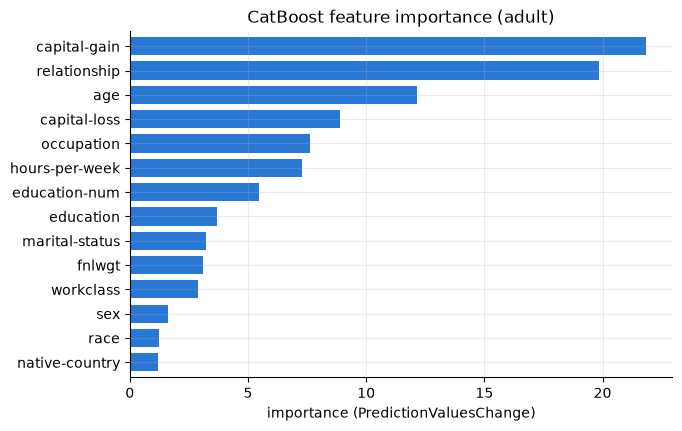

In [4]:
imp = pd.Series(model.get_feature_importance(), index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
imp.plot.barh(ax=ax, color=PALETTE[0], width=0.75); ax.set_xlabel("importance (PredictionValuesChange)")
ax.set_title("CatBoost feature importance (adult)")
plt.show()

## 2. Why ordered target statistics matter: high-cardinality categoricals

Simulate a dataset with:
- `store`: 1,000 levels, each with a genuine effect on $y$
- `customer_id`: 5,000 levels, **pure noise** (≈2 rows each)
- one numeric feature

**Naive target encoding** (replace each level by its mean $y$ over the training set) makes `customer_id` look extremely predictive *on the training data*, because each level's mean is mostly its own row's label. The model leans on it and fails on new data.
Fixes: out-of-fold target encoding (sklearn `TargetEncoder` does cross-fitting), or let CatBoost do it.

In [5]:
import lightgbm as lgb
from sklearn.preprocessing import TargetEncoder
from sklearn.metrics import r2_score

n = 12000
store = rng.integers(0, 1000, n)
customer = rng.integers(0, 5000, n)
x_num = rng.normal(size=n)
store_effect = rng.normal(size=1000)
yy = store_effect[store] + x_num + rng.normal(scale=1.0, size=n)
D = pd.DataFrame({"store": store.astype(str), "customer_id": customer.astype(str), "x_num": x_num})
D_tr, D_te, yy_tr, yy_te = train_test_split(D, yy, test_size=0.3, random_state=SEED)
cats = ["store", "customer_id"]

def naive_te(train, test, ytrain):
    tr, te = train.copy(), test.copy()
    for c in cats:
        means = pd.Series(ytrain, index=train.index).groupby(train[c]).mean()
        tr[c] = train[c].map(means)
        te[c] = test[c].map(means).fillna(ytrain.mean())
    return tr, te

gbm = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1)
results = {}

tr, te = naive_te(D_tr, D_te, yy_tr)
results["naive target encoding + LGBM"] = r2_score(yy_te, lgb.LGBMRegressor(**gbm).fit(tr, yy_tr).predict(te))

enc = TargetEncoder(random_state=SEED)      # fit_transform uses internal cross-fitting
tr, te = D_tr.copy(), D_te.copy()
tr[cats] = enc.fit_transform(D_tr[cats], yy_tr); te[cats] = enc.transform(D_te[cats])
results["out-of-fold TargetEncoder + LGBM"] = r2_score(yy_te, lgb.LGBMRegressor(**gbm).fit(tr, yy_tr).predict(te))

cb = CatBoostRegressor(iterations=800, learning_rate=0.05, depth=6, random_seed=SEED, verbose=0)
results["CatBoost (ordered TS)"] = r2_score(yy_te, cb.fit(D_tr, yy_tr, cat_features=cats).predict(D_te))

pd.Series(results, name="test R²").round(3).to_frame()

,test R²
naive target encoding + LGBM,0.389
out-of-fold TargetEncoder + LGBM,0.559
CatBoost (ordered TS),0.552


The naive encoding is the leakage pattern from notebook 01, in a form that's easy to miss: the encoder "learned" from the very labels the model is trained on.

## 3. Useful CatBoost extras

In [6]:
# Pool bundles data + categorical info (and optional weights, groups, text features).
train_pool = Pool(X_train, y_train, cat_features=cat_cols)
val_pool = Pool(X_val, y_val, cat_features=cat_cols)

# SHAP values come built-in (last column is the expected value / bias).
shap_vals = model.get_feature_importance(val_pool, type="ShapValues")
print("SHAP matrix shape:", shap_vals.shape)

# Feature interactions found by the model
inter = model.get_feature_importance(train_pool, type="Interaction")[:5]
names = X.columns
for a, b, s in inter:
    print(f"{names[int(a)]:>15} × {names[int(b)]:<15} {s:.2f}")

SHAP matrix shape: (7815, 15)
      workclass × occupation      3.33
            age × fnlwgt          2.67
            age × relationship    2.53
     occupation × relationship    2.52
      workclass × fnlwgt          2.37


## Takeaways
- Reach for CatBoost when you have **many or high-cardinality categoricals**, or want strong results with little tuning.
- Pass categoricals as raw strings via `cat_features`; don't one-hot or target-encode them yourself.
- If you *do* target-encode for another model, do it **out-of-fold** (`sklearn.preprocessing.TargetEncoder`).
- Typical tuning: `depth` (4–10), `l2_leaf_reg`, `learning_rate` + early stopping. Use `task_type="GPU"` for big data.